Shape: (10000, 1, 28, 28)
Dtype: float32
Min: 5.56514e-05
Max: 0.69154024


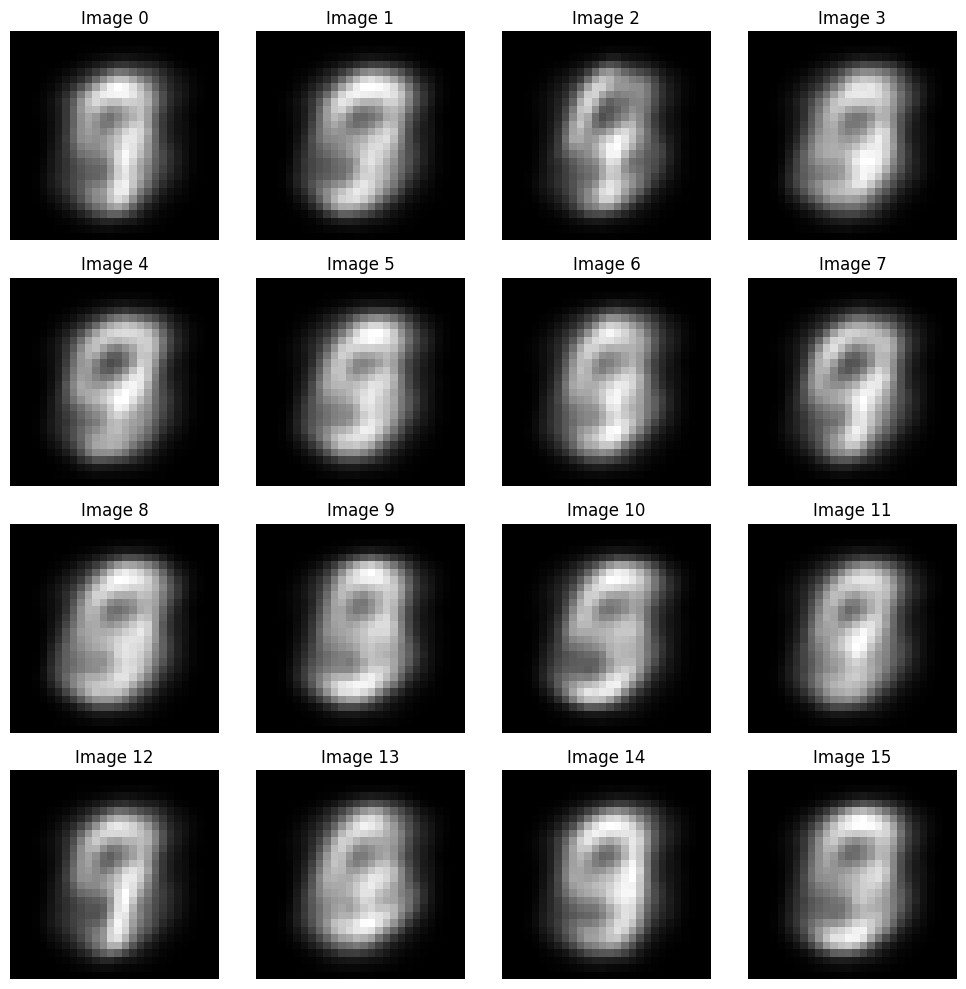

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Path to your .npy file
npy_path = "/Users/lalithkishoresridhar/GitHub/DP_Synthetic_data_generation/results/eval_compare_20261012T173249Z/samples/generated_lvae_gp.npy"

# Load
images = np.load(npy_path)

print("Shape:", images.shape)
print("Dtype:", images.dtype)
print("Min:", images.min())
print("Max:", images.max())

# Number of images to display
n = min(16, len(images))

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
axes = axes.ravel()

for i in range(n):
    img = images[i+100]

    # Handle (C, H, W) -> (H, W, C)
    if img.ndim == 3 and img.shape[0] in [1, 3]:
        img = np.transpose(img, (1, 2, 0))

    # Remove single channel dimension
    if img.ndim == 3 and img.shape[-1] == 1:
        img = img.squeeze(-1)

    # If values are outside [0,1], normalize for visualization
    if img.min() < 0 or img.max() > 1:
        img = (img - img.min()) / (img.max() - img.min() + 1e-8)

    if img.ndim == 2:
        axes[i].imshow(img, cmap="gray")
    else:
        axes[i].imshow(img)

    axes[i].axis("off")
    axes[i].set_title(f"Image {i}")

# Hide unused axes
for i in range(n, len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()